In [28]:
from pathlib import Path

import pandas as pd
try:
    from tqdm.auto import tqdm
except ModuleNotFoundError:
    def tqdm(iterable, **kwargs):
        return iterable
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

In [29]:
# define paths
HERE = Path(_dh[-1])
RESULTS = HERE.parent / "results" / "tables"

In [30]:
# This notebook checks the scaffold top-100 compounds only.
# The unwanted-substructure filter is applied to this docking shortlist,
# not to the full scaffold or random prediction sets.
scaffold_top100_data = pd.read_csv(RESULTS / "top100_docking_results_scaffold.csv")

# this file names the identifier column "compound_id"; rename it so the rest of
# the talktorial code (which expects "molecule_chembl_id") works unchanged
scaffold_top100_data = scaffold_top100_data.rename(columns={"compound_id": "molecule_chembl_id"})

print("Scaffold top-100 dataframe shape:", scaffold_top100_data.shape)
scaffold_top100_data.head()


Scaffold top-100 dataframe shape: (100, 7)


,molecule_chembl_id,smiles,pred_pIC50,pred_IC50_nM,vina_score,ml_rank,docking_rank
0,s_2230__17793196__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...,7.812313,15.405896,-9.973,1,68
1,s_2230__12304850__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...,7.784896,16.409822,-10.369,2,46
2,s_2230__665554__16949512,COC1=CC=CC=C1N2CCN(CC2)CCC3=C(N=C4CCCCN4C3=O)C,7.778951,16.636017,-9.251,3,92
3,s_2230__9292524__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=...,7.767475,17.081462,-10.809,4,18
4,s_2230__14934458__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=...,7.729491,18.642729,-10.317,5,49


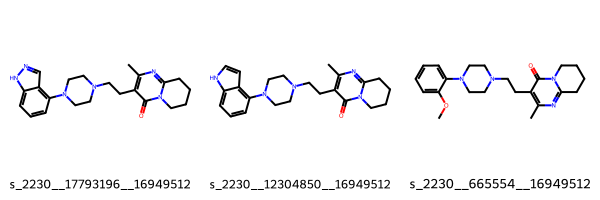

In [31]:
# Draw first 3 scaffold top-100 molecules
mols = [Chem.MolFromSmiles(smiles) for smiles in scaffold_top100_data.head(3)["smiles"]]

Chem.Draw.MolsToGridImage(
    mols,
    legends=list(scaffold_top100_data.head(3).molecule_chembl_id),
)


In [32]:
# initialize filter
params = FilterCatalogParams()
params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
catalog = FilterCatalog(params)

In [33]:
# search for PAINS in the scaffold top-100 set
matches = []
clean = []
for index, row in tqdm(scaffold_top100_data.iterrows(), total=scaffold_top100_data.shape[0]):
    molecule = Chem.MolFromSmiles(row.smiles)
    entry = catalog.GetFirstMatch(molecule)  # Get the first matching PAINS
    if entry is not None:
        # store PAINS information
        matches.append(
            {
                "chembl_id": row.molecule_chembl_id,
                "rdkit_molecule": molecule,
                "pains": entry.GetDescription().capitalize(),
            }
        )
    else:
        # collect indices of molecules without PAINS
        clean.append(index)

matches = pd.DataFrame(matches)
scaffold_top100_data = scaffold_top100_data.loc[clean]  # keep scaffold top-100 molecules without PAINS


In [34]:
# NBVAL_CHECK_OUTPUT
print(f"Number of compounds with PAINS in scaffold top-100 set: {len(matches)}")
print(f"Number of compounds without PAINS in scaffold top-100 set: {len(scaffold_top100_data)}")


Number of compounds with PAINS in scaffold top-100 set: 1
Number of compounds without PAINS in scaffold top-100 set: 99


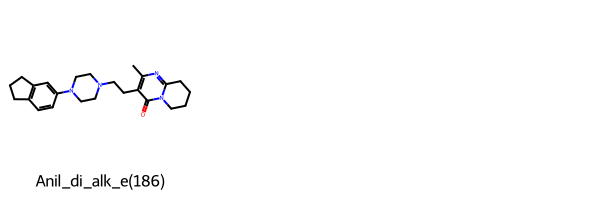

In [35]:
Chem.Draw.MolsToGridImage(
    list(matches.head(3).rdkit_molecule),
    legends=list(matches.head(3)["pains"]),
)

In [ ]:
params = FilterCatalogParams()
params.AddCatalog(FilterCatalogParams.FilterCatalogs.BRENK)
unwanted_catalog = FilterCatalog(params)
print("Number of unwanted substructures in collection:", unwanted_catalog.GetNumEntries())
# NBVAL_CHECK_OUTPUT

In [ ]:
pd.DataFrame(
    {
        "unwanted_substructure": [
            unwanted_catalog.GetEntryWithIdx(i).GetDescription()
            for i in range(2, 5)
        ]
    }
)

In [ ]:
# search for unwanted substructure in the scaffold top-100 set
matches = []
clean = []
for index, row in tqdm(scaffold_top100_data.iterrows(), total=scaffold_top100_data.shape[0]):
    molecule = Chem.MolFromSmiles(row.smiles)
    match = False
    for substructure in unwanted_catalog.GetMatches(molecule):
        filter_matches = substructure.GetFilterMatches(molecule)
        atom_indices = [pair.target for pair in filter_matches[0].atomPairs]
        matches.append(
            {
                "chembl_id": row.molecule_chembl_id,
                "rdkit_molecule": molecule,
                "matched_atoms": atom_indices,
                "substructure_name": substructure.GetDescription(),
            }
        )
        match = True
    if not match:
        clean.append(index)

matches = pd.DataFrame(matches)
scaffold_top100_data = scaffold_top100_data.loc[clean]


In [ ]:
# NBVAL_CHECK_OUTPUT
print(f"Number of found unwanted substructures in scaffold top-100 set: {len(matches)}")
print(f"Number of scaffold top-100 compounds without unwanted substructure: {len(scaffold_top100_data)}")


In [ ]:
to_highlight = list(matches.head(3).matched_atoms)
Chem.Draw.MolsToGridImage(
    list(matches.head(3).rdkit_molecule),
    highlightAtomLists=to_highlight,
    legends=list(matches.head(3).substructure_name),
)

In [ ]:
# NBVAL_CHECK_OUTPUT
groups = matches.groupby("substructure_name")
group_frequencies = groups.size()
group_frequencies.sort_values(ascending=False, inplace=True)
group_frequencies.head(10)